# Quickstart: direct probability and conditional samples

Install the local package with `pip install '.[notebooks,matching,codes]'`, then select that environment as the kernel. This notebook uses the same toric d=5 bit-flip probability p=0.1 as the command-line PyMatching example. All random seeds come from one fixed root seed. The associated paper is in preparation.

In [1]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display
from mcmc4qec import spawn_seeds
QUICK = os.environ.get("MCMC4QEC_QUICK") == "1"
SEED = 2026
print(f"quick={QUICK}; root seed={SEED}")

quick=False; root seed=2026


A `Problem` keeps the code, normalized noise, and deterministic decoder together. Direct Monte Carlo estimates the absolute logical failure probability for a whole experiment. Its Wilson interval describes finite-trial uncertainty.

In [2]:
from mcmc4qec import IndependentBitFlip, Problem, SamplingConfig, direct_mc, sample_faulty
from mcmc4qec.adapters import matching_from_check_matrix
from mcmc4qec.codes import make_toric_code
code = make_toric_code(5)
decoder = matching_from_check_matrix(code.hz, logical_map=code.lz, identifier="toric-d5-mwpm")
problem = Problem(code.bit_flip_model(), IndependentBitFlip(code.n), decoder)
p = 0.1
mc_seed, chain_seed = spawn_seeds(SEED, 2)
mc = direct_mc(problem, p, trials=180 if QUICK else 2000, seed=mc_seed)
print(f"Toric d=5, p={p}: direct MC P_L={mc.estimate:.5f}, Wilson 95%={mc.interval}, failures={mc.failures}")

Toric d=5, p=0.1: direct MC P_L=0.25550, Wilson 95%=(0.23686688696484168, 0.275070549155691), failures=511


The Z+H chain is restricted to failures. Rejections and lazy steps remain in its trace. Its weights estimate `E[w | faulty]`; the fraction of chain states cannot estimate absolute `P_L`. Short runs and diagnostics do not prove convergence, ergodicity, or correctness.

Direct MC E[w|faulty]=7.111545988258317; chain E[w|faulty]=7.420


Actual kernel mixture: {'single': 0.0, 'zanella': 0.6649999999999999, 'cluster': 0.285, 'stabilizer': 0.0, 'physical_fault': 0.0, 'lazy': 0.05}


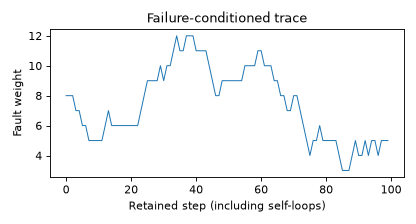

In [3]:
chain = sample_faulty(problem, p, config=SamplingConfig(samples=50 if QUICK else 100,
                                                            burn_in=10 if QUICK else 20), seed=chain_seed)
weights = np.count_nonzero(chain.states, axis=-1).ravel()
print(f"Direct MC E[w|faulty]={mc.conditional_weight}; chain E[w|faulty]={weights.mean():.3f}")
print("Actual kernel mixture:", chain.metadata["config"]["expanded_move_probabilities"])
fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.plot(np.arange(len(weights)), weights, lw=.9)
ax.set(xlabel="Retained step (including self-loops)", ylabel="Fault weight", title="Failure-conditioned trace")
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=80)
display(Image(data=buffer.getvalue()))
plt.close(fig)